In [1]:
import pandas as pd
import numpy as np
import os
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
PROJECT_DIR = os.path.abspath("..")

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "cleaned",
    "ChargingRecords_Featured.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (72826, 32)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,IsWeekend,DurationHours,DurationCategory,HourSin,HourCos,MonthSin,MonthCos,DayOfWeekSin,DayOfWeekCos,DemandCategory
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,...,0,3.083333,Long,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,...,0,1.500000,Medium,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,...,0,1.000000,Short,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,...,0,5.733333,Very Long,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,...,1,5.000000,Very Long,-0.965926,2.588190e-01,-1.0,-1.836970e-16,-0.781831,0.623490,High Demand


In [4]:
print("Demand Statistics:")

print(df["Demand"].describe())

print("\nMissing Demand Values:")

print(df["Demand"].isnull().sum())

Demand Statistics:
count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

Missing Demand Values:
0


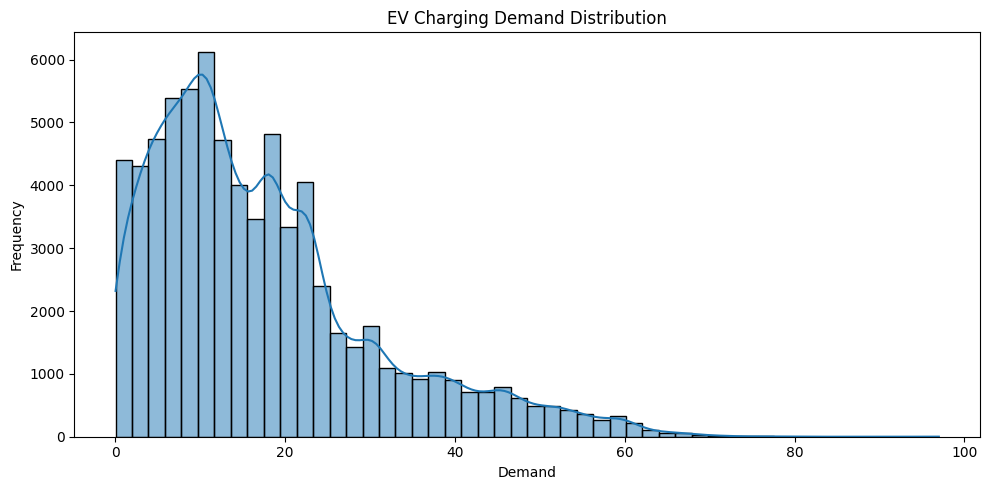

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Demand"].dropna(),
    bins=50,
    kde=True
)

plt.title("EV Charging Demand Distribution")

plt.xlabel("Demand")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

In [6]:
target = "Demand"

drop_columns = [
    "Demand",
    "DemandCategory",
    "UserID",
    "ChargerID",
    "StartDay",
    "StartTime",
    "EndDay",
    "EndTime",
    "StartDatetime",
    "EndDatetime",
    "CalculatedDuration",
    "Duration",
    "DurationHours",
    "DurationCategory"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df[target]

# Remove rows with missing target values
valid_indices = y.notna()

X = X.loc[valid_indices].copy()

y = y.loc[valid_indices].copy()

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nSelected Features:")

print(X.columns.tolist())

Features Shape: (72826, 18)
Target Shape: (72826,)

Selected Features:
['ChargerCompany', 'Location', 'ChargerType', 'Year', 'Month', 'Day', 'DayOfWeek', 'WeekOfYear', 'Quarter', 'Hour', 'Minute', 'IsWeekend', 'HourSin', 'HourCos', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos']


In [7]:
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Treat these columns as categorical even if stored as numbers
for column in [
    "ChargerCompany",
    "ChargerType",
    "Location",
    "TimeOfDay"
]:

    if column in X.columns and column not in categorical_columns:

        categorical_columns.append(column)

numerical_columns = [
    column for column in X.columns
    if column not in categorical_columns
]

# Convert categorical columns to strings
for column in categorical_columns:

    X[column] = X[column].astype("string")

print("Numerical Features:")

print(numerical_columns)

print("\nCategorical Features:")

print(categorical_columns)

Numerical Features:
['Year', 'Month', 'Day', 'DayOfWeek', 'WeekOfYear', 'Quarter', 'Hour', 'Minute', 'IsWeekend', 'HourSin', 'HourCos', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos']

Categorical Features:
['Location', 'ChargerCompany', 'ChargerType']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (58260, 18)
Testing Data: (14566, 18)


In [9]:
numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_columns
        ),
        (
            "cat",
            categorical_transformer,
            categorical_columns
        )
    ]
)

In [10]:
models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

In [11]:
try:

    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )

except ImportError:

    print("XGBoost is not installed.")


try:

    from lightgbm import LGBMRegressor

    models["LightGBM"] = LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

except ImportError:

    print("LightGBM is not installed.")


print("Available Models:")

print(list(models.keys()))

Available Models:
['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']


In [12]:
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "Training Completed")


Training: Linear Regression
Linear Regression Training Completed

Training: Decision Tree
Decision Tree Training Completed

Training: Random Forest
Random Forest Training Completed

Training: Gradient Boosting
Gradient Boosting Training Completed

Training: XGBoost
XGBoost Training Completed

Training: LightGBM
LightGBM Training Completed


In [13]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2 Score": r2

    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
5,LightGBM,9.323141,153.192134,12.377081,0.149868
4,XGBoost,9.318109,153.365877,12.384098,0.148904
3,Gradient Boosting,9.448766,156.605021,12.514193,0.130928
0,Linear Regression,9.664380,162.167850,12.734514,0.100058
2,Random Forest,9.798245,167.025848,12.923848,0.073099
1,Decision Tree,13.322411,327.157673,18.087500,-0.815545


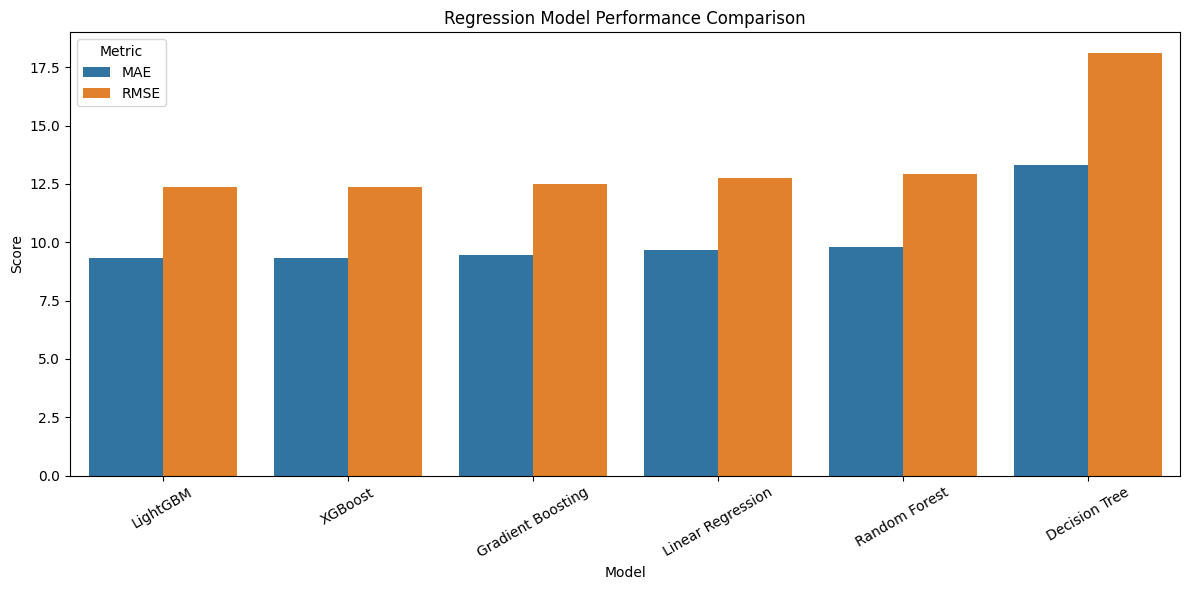

In [14]:
metrics = [
    "MAE",
    "RMSE"
]

plt.figure(figsize=(12, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Regression Model Performance Comparison")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

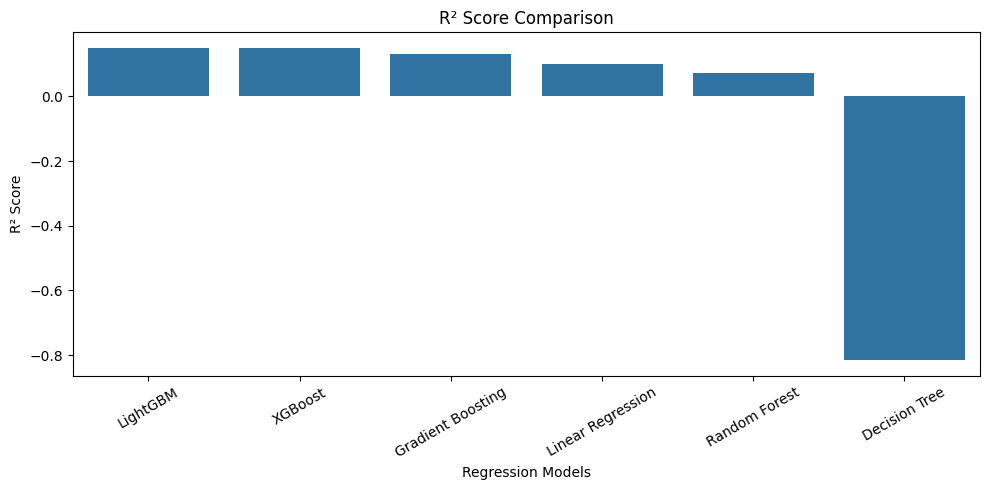

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R² Score Comparison")

plt.xlabel("Regression Models")

plt.ylabel("R² Score")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [16]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Regression Model:", best_model_name)

print("\nBest Model Performance:")

print(results_df.iloc[0])

Best Regression Model: LightGBM

Best Model Performance:
Model         LightGBM
MAE           9.323141
MSE         153.192134
RMSE         12.377081
R2 Score      0.149868
Name: 5, dtype: object


In [17]:
y_pred_best = best_model.predict(X_test)

prediction_results = pd.DataFrame({

    "Actual Demand": y_test.values,

    "Predicted Demand": y_pred_best,

    "Prediction Error": y_test.values - y_pred_best

})

prediction_results.head(20)

,Actual Demand,Predicted Demand,Prediction Error
0,10.32,15.862816,-5.542816
1,30.40,13.440629,16.959371
2,15.00,12.358872,2.641128
3,13.18,16.017810,-2.837810
4,42.30,30.047557,12.252443
5,0.11,10.820415,-10.710415
6,17.20,26.030301,-8.830301
7,30.31,20.228259,10.081741
8,22.53,17.919966,4.610034
9,11.00,16.294784,-5.294784


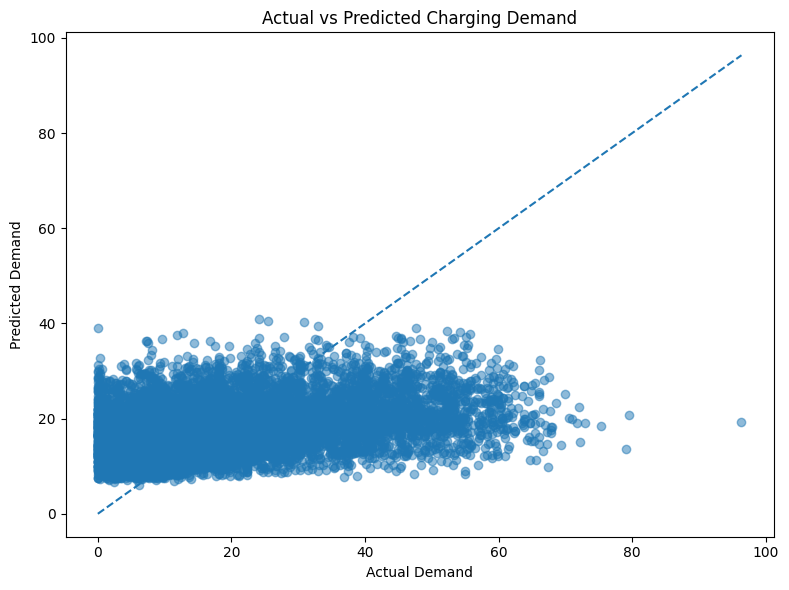

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.5
)

min_value = min(y_test.min(), y_pred_best.min())

max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Charging Demand")

plt.xlabel("Actual Demand")

plt.ylabel("Predicted Demand")

plt.tight_layout()

plt.show()

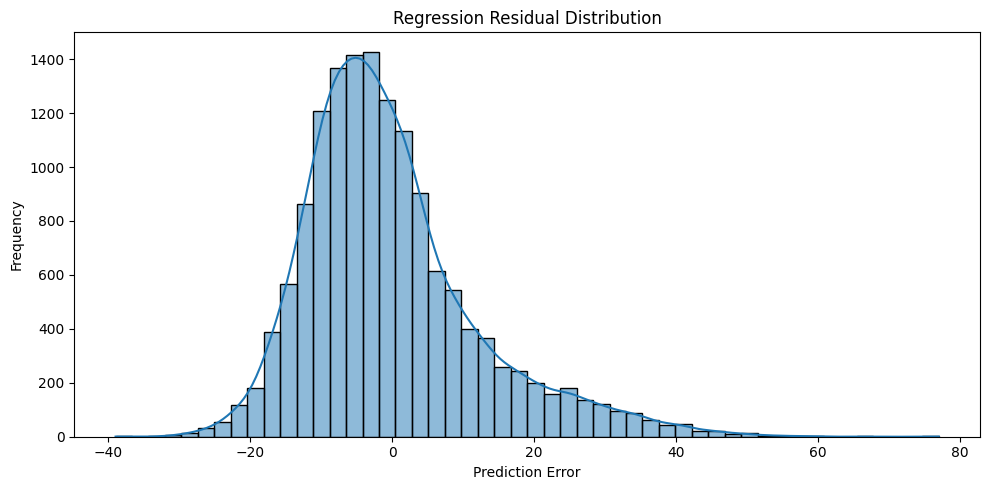

In [19]:
residuals = y_test.values - y_pred_best

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.title("Regression Residual Distribution")

plt.xlabel("Prediction Error")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

In [20]:
results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "regression_model_comparison.csv"
    ),
    index=False
)

print("Regression Model Results Saved Successfully!")

Regression Model Results Saved Successfully!


In [21]:
prediction_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "regression_predictions.csv"
    ),
    index=False
)

print("Prediction Results Saved Successfully!")

Prediction Results Saved Successfully!


In [22]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_regression_model.pkl"
)

joblib.dump(
    best_model,
    MODEL_PATH
)

print("Best Regression Model Saved Successfully!")

print("Model:", best_model_name)

print("Location:", MODEL_PATH)

Best Regression Model Saved Successfully!
Model: LightGBM
Location: c:\Users\yendl\OneDrive\Documents\GUVI Folder\ev-charging_project\models\best_regression_model.pkl
